# Khám phá dữ liệu AAPL — trước preprocessing

Mục tiêu: nhìn thấy dữ liệu, hiểu giá điều chỉnh, kiểm tra chất lượng và xác định phần TV1 cần bổ sung.

**Đi tới kết quả mới nhất:** [TỔNG AUDIT TV1 VÀ KẾT QUẢ DATA](#tv1-final-audit). Bảng nghiệm thu đủ 10 hạng mục và dữ liệu hiện tại nằm ngay sau cell cấu hình. Các mục [10](#tv1-hang-muc-10), [9](#tv1-hang-muc-9), [8](#tv1-hang-muc-8), [7](#tv1-hang-muc-7) giữ nguyên phía dưới.

**Theo dõi tiến độ:** các hạng mục 1, 3–9 có bằng chứng thực thi; mục 10 có hướng dẫn và kết quả kiểm chứng bên dưới. Hạng mục 2 đã cung cấp đủ artifacts; xác nhận người nhận/máy thành viên khác vẫn chờ, không được thay bằng kết quả cùng máy.

**Nguồn hiện tại:** snapshot mới đã tải bằng downloader TV1 ngày 19/11/2026, version `aapl_2015_2025_acq_20261119T141302002415Z`. Đây không phải snapshot EDA cũ hay bộ artifacts tác giả PR đã báo cáo. Notebook mặc định chỉ đọc file có sẵn, không tự tải khi thiếu file. Không fit scaler, không huấn luyện hay chọn cấu hình từ test. Thống kê cả giai đoạn ở đây chỉ phục vụ mô tả chất lượng dữ liệu.

Chạy từ thư mục repo hoặc notebooks. Chọn kernel `.venv/eda/Scripts/python.exe`, đã cài dependencies từ `requirements-eda.txt`. Notebook không ép nạp thư viện của môi trường Python khác. Khi muốn xem snapshot TV1, đặt `TV1_RAW` và `TV1_METADATA` ở cell tiếp theo.

In [1]:
from pathlib import Path
import sys, json, hashlib, importlib.metadata
from datetime import datetime, timezone
ROOT = Path.cwd().resolve()
if not (ROOT / 'docs').exists():
    ROOT = ROOT.parent
assert (ROOT / 'docs/12_Team_Assignment.md').exists(), 'Mở notebook từ repo hoặc notebooks/'
print('Kernel Python:', sys.executable)
print('Python version:', sys.version.split()[0])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 15)
plt.rcParams['figure.figsize'] = (12, 4)
DATASET_VERSION = 'aapl_2015_2025_acq_20261119T141302002415Z'
TV1_RAW = ROOT / f'data/raw/aapl_raw_{DATASET_VERSION}.csv'
TV1_METADATA = ROOT / f'data/metadata/aapl_metadata_{DATASET_VERSION}.json'
OUT = ROOT / 'data/metadata/eda' / DATASET_VERSION
OUT.mkdir(parents=True, exist_ok=True)
EDA_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
EDA_OUT = OUT / EDA_RUN_ID
EDA_OUT.mkdir(parents=True, exist_ok=True)
FIGURES = []
def save_eda_figure(figure, name):
    path = ROOT / f'reports/figures/{DATASET_VERSION}_{EDA_RUN_ID}_{name}.png'
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(path, dpi=150, bbox_inches='tight')
    FIGURES.append(path.relative_to(ROOT).as_posix())
print('Project:', ROOT)


Kernel Python: D:\learn_DeepLearning\Project_course-work\.venv\tv1_clean\Scripts\python.exe
Python version: 3.13.7


Project: D:\learn_DeepLearning\Project_course-work


<a id="tv1-final-audit"></a>

## TỔNG AUDIT TV1 VÀ KẾT QUẢ DATA

Đối chiếu lại `rule.md`, phân công TV1 và Data Flow Contract, chạy lại tests trên môi trường sạch và xác minh artifacts/ZIP/Drive metadata. Đây là tổng kết bằng chứng, không coi các báo cáo cũ ghi “đạt” là đủ.

**Kết luận:** dữ liệu và implementation TV1 đạt các kiểm tra cục bộ, có thể chuyển bảng chuẩn cho TV2. **Chưa nghiệm thu trọn checklist bàn giao:** mục 2 và 10 còn xác nhận người nhận/máy thành viên khác. Không tự tính cùng máy là xác nhận độc lập. Các giới hạn lịch tham chiếu, giá hồi cứu và bằng chứng tin tức giữ nguyên.

Cell dưới đọc audit đã thực thi, kiểm tra hash data chưa đổi và hiển thị đủ 10 hạng mục, số liệu cùng mẫu dữ liệu thực. Muốn audit lại chạy `scripts/audit_tv1_completion.py --dataset-version <version>` sau runner tests.

In [2]:
final_pointer_path = ROOT/'data/metadata/tv1_final_audit_latest.json'
if final_pointer_path.exists():
    final_pointer = json.loads(final_pointer_path.read_text(encoding='utf-8'))
    final_audit_path = ROOT/final_pointer['summary']
    final_audit = json.loads(final_audit_path.read_text(encoding='utf-8'))
    assert final_audit['dataset_version']==DATASET_VERSION
    for name, expected_hash in final_audit['artifact_hashes'].items():
        assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==expected_hash, f'Data đã thay đổi sau audit: {name}'
    display(pd.DataFrame(final_audit['matrix']).rename(columns={'item':'Hạng mục','name':'Nội dung','local_passed':'Đạt tại máy','status':'Nghiệm thu'}))
    display(pd.Series({'Audit run':final_audit['audit_run_id'],'Đạt kỹ thuật cục bộ':final_audit['all_local_requirements_passed'],'Sẵn sàng chuyển TV2 tại máy':final_audit['ready_for_TV2_locally'],'Nghiệm thu bàn giao độc lập đầy đủ':final_audit['fully_accepted'],'Tests đạt':final_audit['tests_run'],'Failure/error/skip':f"{final_audit['test_failures']}/{final_audit['test_errors']}/{final_audit['test_skipped']}",'Hash artifacts không đổi':final_audit['artifacts_unchanged']},name='Kết luận').to_frame())
    fd=final_audit['data']
    display(pd.Series({key:fd[key] for key in ['raw_rows','validated_rows','first_date','last_date','return_count','rows_removed']},name='Kết quả dữ liệu').to_frame())
    display(pd.Series(fd['price_summary_usd'],name='Adjusted close USD').to_frame())
    display(pd.Series(fd['return_summary_pct'],name='Daily return %').to_frame())
    display(pd.Series(fd['split_session_counts'],name='Số phiên trước windowing').to_frame())
    print('Schema:',fd['schema']); print('Phiên thiếu/thừa:',fd['missing_sessions'],fd['unexpected_sessions'])
    print('5 phiên biến động đã xem xét, giữ nguyên:',fd['flagged_dates'])
    final_table=pd.read_csv(ROOT/f'data/validated/aapl_validated_{DATASET_VERSION}.csv')
    display(final_table.head(5));display(final_table.tail(5))
    display(pd.Series(final_audit['artifact_hashes'],name='SHA256').to_frame())
    display(Markdown(f"**Còn lại:** xác nhận thành viên khác nhận và chạy đúng bộ (mục 2/10). Scaler/windowing/model/train không phải phần TV1 còn thiếu. [Báo cáo audit](../reports/audits/TV1_Final_Audit.md) · [Audit JSON](../{final_pointer['summary']})."))
else:
    display(Markdown('Chưa có tổng audit tại workspace này; chạy runner tests rồi scripts/audit_tv1_completion.py. Không tự ghi nghiệm thu đầy đủ.'))


,Hạng mục,Nội dung,Đạt tại máy,Nghiệm thu
0,1,Thu thập dữ liệu,True,Đạt cục bộ
1,2,Bàn giao snapshot,True,Đạt phần cung cấp/cục bộ; chờ xác nhận độc lập
2,3,Metadata và nguồn gốc,True,Đạt cục bộ
3,4,Bảo vệ phiên bản,True,Đạt cục bộ
4,5,Kiểm tra chất lượng,True,Đạt cục bộ
5,6,Xuất/xác minh dữ liệu chuẩn,True,Đạt cục bộ
6,7,Khám phá dữ liệu,True,Đạt cục bộ
7,8,Điều tra bất thường,True,Đạt cục bộ
8,9,Kiểm thử,True,Đạt cục bộ
9,10,Tài liệu và tái lập,True,Đạt phần cung cấp/cục bộ; chờ xác nhận độc lập


,Kết luận
Audit run,20261119T161110977852Z
Đạt kỹ thuật cục bộ,True
Sẵn sàng chuyển TV2 tại máy,True
Nghiệm thu bàn giao độc lập đầy đủ,False
Tests đạt,34
Failure/error/skip,0/0/0
Hash artifacts không đổi,True


,Kết quả dữ liệu
raw_rows,2766
validated_rows,2766
first_date,2015-01-02
last_date,2025-12-31
return_count,2765
rows_removed,0


,Adjusted close USD
count,2766.000000
mean,105.955528
std,74.063170
min,20.532551
25%,36.524208
50%,88.164150
75%,168.061726
max,285.196411


,Daily return %
count,2765.000000
mean,0.103949
std,1.817116
min,-12.864718
1%,-4.807295
99%,4.944709
max,15.328870


,Số phiên trước windowing
train_2015_2022,2014
validation_2023,250
test_2024_2025,502


Schema: ['date', 'ticker', 'adjusted_close', 'dataset_version']
Phiên thiếu/thừa: [] []
5 phiên biến động đã xem xét, giữ nguyên: ['2020-03-13', '2020-03-16', '2020-03-24', '2020-07-31', '2025-04-09']


,date,ticker,adjusted_close,dataset_version
0,2015-01-02,AAPL,24.153402,aapl_2015_2025_acq_20261119T141302002415Z
1,2015-01-05,AAPL,23.472971,aapl_2015_2025_acq_20261119T141302002415Z
2,2015-01-06,AAPL,23.475178,aapl_2015_2025_acq_20261119T141302002415Z
3,2015-01-07,AAPL,23.804344,aapl_2015_2025_acq_20261119T141302002415Z
4,2015-01-08,AAPL,24.718971,aapl_2015_2025_acq_20261119T141302002415Z


,date,ticker,adjusted_close,dataset_version
2761,2025-12-24,AAPL,272.859375,aapl_2015_2025_acq_20261119T141302002415Z
2762,2025-12-26,AAPL,272.450836,aapl_2015_2025_acq_20261119T141302002415Z
2763,2025-12-29,AAPL,272.809601,aapl_2015_2025_acq_20261119T141302002415Z
2764,2025-12-30,AAPL,272.131897,aapl_2015_2025_acq_20261119T141302002415Z
2765,2025-12-31,AAPL,270.916168,aapl_2015_2025_acq_20261119T141302002415Z


,SHA256
data/raw/aapl_raw_aapl_2015_2025_acq_20261119T141302002415Z.csv,cbcadbc002d05bc27a573114b9bb73b930733585b7823d...
data/metadata/aapl_metadata_aapl_2015_2025_acq_20261119T141302002415Z.json,71213959ec9c111a1826db9058dc41f61772af9a0324a4...
data/validated/aapl_validated_aapl_2015_2025_acq_20261119T141302002415Z.csv,ee56f9c782ac9e938985c680a9015d1ae198982e7d1cdd...
data/metadata/aapl_validation_report_aapl_2015_2025_acq_20261119T141302002415Z.json,4c28421c1488cfa3451fbd9661eed9fc4874a9295389e9...


**Còn lại:** xác nhận thành viên khác nhận và chạy đúng bộ (mục 2/10). Scaler/windowing/model/train không phải phần TV1 còn thiếu. [Báo cáo audit](../reports/audits/TV1_Final_Audit.md) · [Audit JSON](../data/metadata/tv1_final_audit_20261119T161110977852Z/summary.json).

## 1. TV1 — Thu thập dữ liệu (đã thực hiện)

**Mục tiêu:** tải AAPL theo phiên ngày, 2015-01-01 đến 2025-12-31, giữ raw và metadata/hash. Downloader gọi Yahoo qua yfinance với `interval="1d"`, `auto_adjust=False`, `end="2026-01-01"` vì end không bao gồm ngày cuối. Giữ OHLCV để đối chiếu; project dùng Adj Close, đơn vị USD. Giá đã điều chỉnh hồi cứu không phải giá point-in-time.

Lần tải đã chạy bằng `backend/data/acquisition/downloader.py`. Đoạn dưới minh họa lệnh tái lập, **không tự thực thi khi Run All**. Khi cần tải mới, dùng version mới, không dùng lại version đã có:

```python
from backend.data.acquisition.downloader import download_aapl_snapshot
from datetime import datetime, timezone
version = 'aapl_2015_2025_acq_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
metadata = download_aapl_snapshot(
    dataset_version=version,
    raw_dir=ROOT / 'data/raw',
    metadata_dir=ROOT / 'data/metadata',
)
```

Downloader đã được bổ sung tự chặn ghi đè ở hạng mục 4 bên dưới. Bằng chứng lần tải: [báo cáo thu thập](../reports/audits/TV1_Acquisition_20261119T141302002415Z.md). Các cell tiếp theo đọc lại snapshot đó để kiểm tra đầu ra thu thập; chưa phải nghiệm thu validation.

In [3]:
raw_path = TV1_RAW
if not raw_path.is_file() or not TV1_METADATA.is_file():
    raise FileNotFoundError('Thiếu raw/metadata snapshot TV1. Nhận đúng artifacts theo báo cáo thu thập; không tự tải thay thế.')
metadata = json.loads(TV1_METADATA.read_text(encoding='utf-8'))
origin = 'New snapshot collected using TV1 downloader; not the original PR artifacts'
actual_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()
expected_hash = metadata.get('raw_sha256', metadata.get('sha256'))
print(origin)
display(pd.Series(metadata, name='Provenance').to_frame())
print('Actual SHA256:', actual_hash)
assert expected_hash is not None and actual_hash == expected_hash, 'Thiếu/sai hash: dừng đọc snapshot này'
raw = pd.read_csv(raw_path)
print('Rows/columns:', raw.shape)
acquisition_checks = {
    'SHA-256 khớp metadata': actual_hash == expected_hash,
    'Dataset version khớp': metadata['dataset_version'] == DATASET_VERSION,
    'Nguồn AAPL / USD': metadata['ticker'] == 'AAPL' and metadata['currency'] == 'USD',
    'Đường dẫn raw khớp': (ROOT / metadata['raw_file']).resolve() == raw_path.resolve(),
    'Số dòng khớp metadata': len(raw) == metadata['row_count'],
    'Schema khớp metadata': list(raw.columns) == metadata['columns'],
    'Ngày đầu/cuối khớp metadata': not raw.empty and raw.date.iloc[0] == metadata['actual_first_date'] and raw.date.iloc[-1] == metadata['actual_last_date'],
}
display(pd.Series(acquisition_checks, name='PASS').to_frame())
assert all(acquisition_checks.values()), 'Đầu ra thu thập chưa nhất quán'
display(Markdown('### Dữ liệu đầu và cuối snapshot'))
display(raw.head(10)); display(raw.tail(10))
display(Markdown(f"**Hoàn thành hạng mục thu thập:** {len(raw):,} dòng, {len(raw.columns)} cột; phiên đầu {raw.date.iloc[0]}, phiên cuối {raw.date.iloc[-1]}. Raw và metadata đã lưu đúng thư mục; hash và thông tin đầu ra đã đối chiếu. Các mục 2–6 phía dưới là khám phá/audit bổ sung, không phải xác nhận đã chạy validator TV1."))


New snapshot collected using TV1 downloader; not the original PR artifacts


,Provenance
dataset_version,aapl_2015_2025_acq_20261119T141302002415Z
ticker,AAPL
source,Yahoo Finance (yfinance)
yfinance_version,1.8.0
downloaded_at_utc,2026-11-19T14:13:03.596814+00:00
currency,USD
requested_start_date,2015-01-01
requested_end_date,2025-12-31
actual_first_date,2015-01-02
actual_last_date,2025-12-31


Actual SHA256: cbcadbc002d05bc27a573114b9bb73b930733585b7823d147ca3477354479351
Rows/columns: (2766, 7)


,PASS
SHA-256 khớp metadata,True
Dataset version khớp,True
Nguồn AAPL / USD,True
Đường dẫn raw khớp,True
Số dòng khớp metadata,True
Schema khớp metadata,True
Ngày đầu/cuối khớp metadata,True


### Dữ liệu đầu và cuối snapshot

,date,Adj Close,Close,High,Low,Open,Volume
0,2015-01-02,24.153402,27.332500,27.860001,26.837500,27.847500,212818400
1,2015-01-05,23.472971,26.562500,27.162500,26.352501,27.072500,257142000
2,2015-01-06,23.475178,26.565001,26.857500,26.157499,26.635000,263188400
3,2015-01-07,23.804344,26.937500,27.049999,26.674999,26.799999,160423600
4,2015-01-08,24.718971,27.972500,28.037500,27.174999,27.307501,237458000
5,2015-01-09,24.745478,28.002501,28.312500,27.552500,28.167500,214798000
6,2015-01-12,24.135735,27.312500,28.157499,27.200001,28.150000,198603200
7,2015-01-13,24.350025,27.555000,28.200001,27.227501,27.857500,268367600
8,2015-01-14,24.257238,27.450001,27.622499,27.125000,27.260000,195826400
9,2015-01-15,23.598888,26.705000,27.514999,26.665001,27.500000,240056000


,date,Adj Close,Close,High,Low,Open,Volume
2756,2025-12-17,270.896240,271.839996,276.160004,271.640015,275.010010,50138700
2757,2025-12-18,271.245026,272.190002,273.630005,266.950012,273.609985,51630700
2758,2025-12-19,272.719879,273.670013,274.600006,269.899994,272.149994,144632000
2759,2025-12-22,270.029297,270.970001,273.880005,270.510010,272.859985,36571800
2760,2025-12-23,271.414398,272.359985,272.500000,269.559998,270.839996,29642000
2761,2025-12-24,272.859375,273.809998,275.429993,272.200012,272.339996,17910600
2762,2025-12-26,272.450836,273.399994,275.369995,272.859985,274.160004,21521800
2763,2025-12-29,272.809601,273.760010,274.359985,272.350006,272.690002,23715200
2764,2025-12-30,272.131897,273.079987,274.079987,272.279999,272.809998,22139600
2765,2025-12-31,270.916168,271.859985,273.679993,271.750000,273.059998,27293600


**Hoàn thành hạng mục thu thập:** 2,766 dòng, 7 cột; phiên đầu 2015-01-02, phiên cuối 2025-12-31. Raw và metadata đã lưu đúng thư mục; hash và thông tin đầu ra đã đối chiếu. Các mục 2–6 phía dưới là khám phá/audit bổ sung, không phải xác nhận đã chạy validator TV1.

### Biên bản hoàn thành hạng mục TV1 số 1

| Nội dung | Bằng chứng |
|---|---|
| Công việc đã thực hiện | Gọi downloader TV1 để tải snapshot AAPL 2015–2025, lưu raw CSV và metadata |
| Lúc thu thập | 19/11/2026, 21:13 giờ Việt Nam — timestamp chính xác hiển thị trong metadata phía trên |
| Dataset version | `aapl_2015_2025_acq_20261119T141302002415Z` |
| Kết quả đã nhận | 2.766 dòng, 7 cột; 2015-01-02 đến 2025-12-31 |
| Kiểm tra hoàn tất | 7 phép đối chiếu đầu ra ở bảng PASS phía trên; bao gồm hash, version, đường dẫn, schema và số dòng |
| Raw CSV | [Mở snapshot](../data/raw/aapl_raw_aapl_2015_2025_acq_20261119T141302002415Z.csv) |
| Metadata | [Mở metadata](../data/metadata/aapl_metadata_aapl_2015_2025_acq_20261119T141302002415Z.json) |
| Báo cáo thực hiện | [Mở bằng chứng thu thập](../reports/audits/TV1_Acquisition_20261119T141302002415Z.md) |
| Không thay đổi dữ liệu cũ | Dùng version mới; không ghi đè snapshot EDA hay bộ TV1 đã báo cáo trước đây |

**Trạng thái: hoàn thành thu thập cục bộ.** Bảng đầu/cuối và metadata đã có output thực. Chưa công bố hoàn thành bàn giao artifacts cho thành viên khác, chưa chạy pipeline validator để xuất validated CSV, chưa preprocessing. Raw và metadata bị loại khỏi Git đúng chính sách project; đường dẫn trên chỉ mở được khi có artifacts tại máy.

**Việc tiếp theo:** kiểm định chất lượng snapshot này và ghi kết quả tương ứng vào notebook khi hoàn thành. Việc tự chặn ghi đè được triển khai riêng tại hạng mục 4.

## Hạng mục TV1 số 2 — Bàn giao snapshot

**Trạng thái: đã chuẩn bị và upload đủ bộ artifacts; chờ xác nhận độc lập của người nhận.** Gói đầy đủ gồm raw CSV, validated CSV, metadata nguồn, validation report, script kiểm tra dùng Python chuẩn, manifest và hướng dẫn. Gói raw-only trước đó được giữ làm lịch sử. Đây không phải model/scaler release; việc hoàn tất bộ file không thay thế audit chất lượng đầy đủ ở hạng mục 5.

Người nhận kiểm tra SHA-256 của ZIP bằng `Get-FileHash -Algorithm SHA256 <zip>`, đối chiếu file `.zip.sha256`; giải nén vào gốc project để giữ đường dẫn `data/raw/` và `data/metadata/`, rồi đối chiếu hash từng file theo `manifest.json`. Không ghi đè file khác hash. Clone Git không có dataset do `.gitignore`.

Đã chạy validator trên snapshot cố định, xuất 2.766 dòng validated, đối chiếu từng ngày/giá với raw và upload ZIP đầy đủ cùng checksum vào Drive Project_CW. Chưa xác nhận người khác đã tải hoặc chạy được. Cell dưới kiểm tra lại gói hiện có, không tạo ZIP mới.

In [4]:
import zipfile
handoff_path = ROOT / f'data/metadata/aapl_handoff_{DATASET_VERSION}_complete.json'
handoff = json.loads(handoff_path.read_text(encoding='utf-8'))
archive = ROOT / handoff['archive']
assert hashlib.sha256(archive.read_bytes()).hexdigest() == handoff['archive_sha256']
with zipfile.ZipFile(archive) as bundle:
    assert bundle.testzip() is None
    packaged_manifest = json.loads(bundle.read('manifest.json'))
    assert packaged_manifest['dataset_version'] == DATASET_VERSION
    for item in packaged_manifest['files']:
        assert hashlib.sha256(bundle.read(item['path'])).hexdigest() == item['sha256']
display(pd.Series({key: handoff[key] for key in ['archive','archive_sha256','status','validated_handoff_complete','shared_location','recipient_verified']}, name='Handoff status').to_frame())
display(pd.DataFrame(packaged_manifest['files']))
if handoff.get('requested_folder_url'):
    display(Markdown(f"**Thư mục Drive đích:** [Mở thư mục]({handoff['requested_folder_url']}). Trạng thái upload: `{handoff.get('upload_status', 'not_attempted')}`. {handoff.get('upload_error', '')}"))
if handoff.get('drive_archive'):
    display(Markdown(f"**Tải từ Drive:** [Gói ZIP]({handoff['drive_archive']['url']}) · [Checksum SHA-256]({handoff['drive_checksum']['url']}). Đã xác nhận metadata Drive và thư mục cha; chưa có xác nhận người nhận kiểm tra."))
display(Markdown(f"[Mở gói ZIP](../{handoff['archive']}) — SHA-256 và nội dung đã đối chiếu thành công."))
print('Còn thiếu để bàn giao đủ:', *handoff['missing_validation_artifacts'], sep='\n')


,Handoff status
archive,artifacts/releases/aapl_2015_2025_acq_20261119...
archive_sha256,1aa67d814e5d68b3f275af88443dd31835974463dee152...
status,complete_artifact_set
validated_handoff_complete,True
shared_location,https://drive.google.com/drive/folders/16HyJmt...
recipient_verified,False


,path,sha256,bytes
0,data/raw/aapl_raw_aapl_2015_2025_acq_20261119T...,cbcadbc002d05bc27a573114b9bb73b930733585b7823d...,305762
1,data/metadata/aapl_metadata_aapl_2015_2025_acq...,71213959ec9c111a1826db9058dc41f61772af9a0324a4...,1037
2,data/validated/aapl_validated_aapl_2015_2025_a...,ee56f9c782ac9e938985c680a9015d1ae198982e7d1cdd...,213825
3,data/metadata/aapl_validation_report_aapl_2015...,4c28421c1488cfa3451fbd9661eed9fc4874a9295389e9...,2374
4,scripts/verify_tv1_handoff.py,12fba84d717e825443391428ac19fbde069aa6b3fba364...,4225


**Thư mục Drive đích:** [Mở thư mục](https://drive.google.com/drive/folders/16HyJmtmQ0YzfGHAGGtQ_qTSNEc6lQMwl). Trạng thái upload: `uploaded_metadata_verified`. 

**Tải từ Drive:** [Gói ZIP](https://drive.google.com/file/d/1gfVBtM81snGI6x4rhqkAX6JZE9wavSfY/view?usp=drivesdk) · [Checksum SHA-256](https://drive.google.com/file/d/1j6nN6gRB_xzGvnxbt-fmmHqGSjr_iMM4/view?usp=drivesdk). Đã xác nhận metadata Drive và thư mục cha; chưa có xác nhận người nhận kiểm tra.

[Mở gói ZIP](../artifacts/releases/aapl_2015_2025_acq_20261119T141302002415Z_complete_handoff_20261119T151339704353Z.zip) — SHA-256 và nội dung đã đối chiếu thành công.

Còn thiếu để bàn giao đủ:


### Xác minh bộ bàn giao đầy đủ

Tải ZIP và `.zip.sha256` từ hai link phía trên. Lấy script `scripts/verify_tv1_handoff.py` từ source project. Chạy `python scripts/verify_tv1_handoff.py --archive <zip> --checksum <zip.sha256>`.

Script không cần pandas, không tải mạng, kiểm tra checksum ZIP, đường dẫn thành viên, hash/kích thước, liên kết metadata/report và raw–validated từng dòng. Giải nén vào bản project mới, không ghi đè file khác hash. Người nhận phản hồi version, hash ZIP và output `passed: true` để xác nhận bàn giao độc lập. Cell dưới là xác minh cục bộ, không giả danh người nhận.

In [5]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.verify_tv1_handoff import verify
complete_check = verify(archive, archive.with_suffix('.zip.sha256'))
assert complete_check['passed']
display(pd.Series(complete_check, name='Local verification').to_frame())
validated_path = ROOT / f'data/validated/aapl_validated_{DATASET_VERSION}.csv'
display(pd.read_csv(validated_path).head())
display(Markdown('**Bộ artifacts đã đầy đủ và upload:** không còn thiếu validated/report. **Xác nhận người nhận: đang chờ.** Không coi kiểm tra cục bộ là bằng chứng chạy trên máy thành viên khác.'))


,Local verification
passed,True
dataset_version,aapl_2015_2025_acq_20261119T141302002415Z
zip_sha256,1aa67d814e5d68b3f275af88443dd31835974463dee152...
member_count,7
raw_rows,2766
validated_rows,2766
raw_validated_aligned,True
recipient_verified,False


,date,ticker,adjusted_close,dataset_version
0,2015-01-02,AAPL,24.153402,aapl_2015_2025_acq_20261119T141302002415Z
1,2015-01-05,AAPL,23.472971,aapl_2015_2025_acq_20261119T141302002415Z
2,2015-01-06,AAPL,23.475178,aapl_2015_2025_acq_20261119T141302002415Z
3,2015-01-07,AAPL,23.804344,aapl_2015_2025_acq_20261119T141302002415Z
4,2015-01-08,AAPL,24.718971,aapl_2015_2025_acq_20261119T141302002415Z


**Bộ artifacts đã đầy đủ và upload:** không còn thiếu validated/report. **Xác nhận người nhận: đang chờ.** Không coi kiểm tra cục bộ là bằng chứng chạy trên máy thành viên khác.

## Hạng mục TV1 số 3 — Metadata và nguồn gốc

Gọi phép kiểm tra dùng chung ở `backend/data/validation/provenance.py`: đối chiếu AAPL, USD, version, nguồn khai báo, phiên bản yfinance, khoảng ngày yêu cầu, timestamp UTC, chính sách Adj Close/auto_adjust=False, giới hạn hồi cứu, đường dẫn và hash raw, số dòng/schema/ngày thực tế. Không sửa snapshot hoặc metadata nguồn.

Đây là kiểm tra **tính nhất quán khai báo và tính toàn vẹn cục bộ**: hash không tự chứng minh dữ liệu thực sự đến từ Yahoo hoặc metadata chưa bị sửa cùng raw. Chưa kiểm tra đủ lịch phiên. Validator đã được nối với kiểm tra này; báo cáo validation tương lai sẽ lưu cả hash raw lẫn hash metadata để truy vết raw → validated. Chưa tạo validated CSV trong hạng mục này.

In [6]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # Project source only; never inject another environment's dependencies
from backend.data.validation.provenance import inspect_snapshot_provenance
provenance = inspect_snapshot_provenance(raw_path, metadata, DATASET_VERSION, ROOT)
display(pd.Series(provenance['checks'], name='PASS').to_frame())
assert provenance['passed'], provenance['errors']
provenance['metadata_sha256'] = hashlib.sha256(TV1_METADATA.read_bytes()).hexdigest()
provenance['checked_at_utc'] = datetime.now(timezone.utc).isoformat()
provenance_path = ROOT / f'data/metadata/aapl_provenance_report_{DATASET_VERSION}.json'
provenance_path.write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(f"**Hoàn thành kiểm tra metadata hiện tại:** {len(provenance['checks'])} kiểm tra đạt. Báo cáo: `{provenance_path.relative_to(ROOT)}`. Không thay raw/metadata; chưa nghiệm thu validated hoặc lịch giao dịch."))


,PASS
dataset_version,True
ticker_AAPL,True
currency_USD,True
source_Yahoo_yfinance,True
yfinance_version_present,True
requested_start_date,True
requested_end_date,True
downloaded_at_UTC,True
adjustment_policy,True
retrospective_limitation_present,True


**Hoàn thành kiểm tra metadata hiện tại:** 16 kiểm tra đạt. Báo cáo: `data\metadata\aapl_provenance_report_aapl_2015_2025_acq_20261119T141302002415Z.json`. Không thay raw/metadata; chưa nghiệm thu validated hoặc lịch giao dịch.

## Hạng mục TV1 số 4 — Bảo vệ phiên bản snapshot

Downloader từ chối trước khi gọi mạng nếu raw **hoặc** metadata của version đã tồn tại, kể cả bộ file chưa đầy đủ. Tên version chỉ nhận chữ, số, `_`, `-`. Cả hai file được tạo bằng chế độ exclusive `x` để tránh ghi đè khi nhiều tiến trình cùng chạy. Nếu lỗi được bắt, chỉ dọn các file chính lần gọi đó tạo ra; không sửa/xóa file đã có. Nếu tiến trình bị tắt đột ngột, file dở có thể còn nhưng lần sau vẫn bị chặn để kiểm tra thủ công.

Đây là bảo vệ ở mức ứng dụng; không ngăn người dùng sửa file thủ công hoặc thay quyền hệ điều hành. Dữ liệu mới phải dùng version mới. Cell dưới gọi lại version thật đã có với mạng được mock, xác nhận bị chặn và hash raw/metadata không đổi; không tải mới.

In [7]:
from unittest.mock import patch
from backend.data.acquisition.downloader import download_aapl_snapshot
before = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in [TV1_RAW, TV1_METADATA]}
blocked = False
with patch('backend.data.acquisition.downloader.yf.download') as network:
    try:
        download_aapl_snapshot(DATASET_VERSION, TV1_RAW.parent, TV1_METADATA.parent)
    except FileExistsError as exc:
        blocked = True
        print('Đã chặn:', exc)
    assert blocked, 'Không chặn version đã có'
    network.assert_not_called()
after = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in [TV1_RAW, TV1_METADATA]}
assert before == after
versioning_result = {'dataset_version':DATASET_VERSION, 'existing_version_rejected':blocked, 'network_called':False, 'raw_and_metadata_unchanged':before == after, 'hashes':after, 'checked_at_utc':datetime.now(timezone.utc).isoformat()}
versioning_path = ROOT / f'data/metadata/aapl_versioning_report_{DATASET_VERSION}.json'
versioning_path.write_text(json.dumps(versioning_result,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.Series(versioning_result, name='Kết quả').to_frame())
display(Markdown('**Hoàn thành hạng mục 4:** chặn dùng lại version trước khi tải; raw/metadata hiện tại giữ nguyên. Bằng chứng chi tiết: `reports/audits/TV1_Snapshot_Versioning.md`.'))


Đã chặn: Snapshot already exists: D:\learn_DeepLearning\Project_course-work\data\raw\aapl_raw_aapl_2015_2025_acq_20261119T141302002415Z.csv. Use a new dataset_version.


,Kết quả
dataset_version,aapl_2015_2025_acq_20261119T141302002415Z
existing_version_rejected,True
network_called,False
raw_and_metadata_unchanged,True
hashes,{'D:\learn_DeepLearning\Project_course-work\da...
checked_at_utc,2026-11-19T16:12:43.431082+00:00


**Hoàn thành hạng mục 4:** chặn dùng lại version trước khi tải; raw/metadata hiện tại giữ nguyên. Bằng chứng chi tiết: `reports/audits/TV1_Snapshot_Versioning.md`.

## Hạng mục TV1 số 5 — Kiểm tra chất lượng dữ liệu

Gọi validator dùng chung để kiểm tra cột/ngày, NaN/Inf, giá không dương, trùng/thứ tự, phiên thiếu/thừa, độ phủ 2015–2025 và các cột OHLC/Volume nếu có. Không loại hoặc điền dòng, không dùng tương lai sửa quá khứ. Biến động >10% là cảnh báo cần điều tra ở hạng mục 8, không tự xóa.

Lịch yêu cầu `NASDAQ` được exchange_calendars ánh xạ sang `XNYS`; kết quả ghi rõ tên và phiên bản thư viện. Đây là lịch phiên tham chiếu, không phải xác nhận độc lập của sàn Nasdaq. Khi có sai lệch cần đối chiếu lịch nguồn. Báo cáo audit mới được lưu riêng, không ghi đè validated/report đã đóng gói ở hạng mục 2.

In [8]:
from backend.data.validation.validator import inspect_raw_dataframe
quality, audited_table = inspect_raw_dataframe(raw, DATASET_VERSION)
quality['raw_sha256'] = hashlib.sha256(raw_path.read_bytes()).hexdigest()
quality['source_metadata_sha256'] = hashlib.sha256(TV1_METADATA.read_bytes()).hexdigest()
quality['checked_at_utc'] = datetime.now(timezone.utc).isoformat()
quality['audit_scope'] = 'TV1 item 5; read-only audit of fixed raw snapshot; existing handed-off validation report is preserved.'
quality_path = ROOT / f'data/metadata/aapl_quality_audit_{DATASET_VERSION}.json'
quality_path.write_text(json.dumps(quality,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
display(pd.Series({key:quality[key] for key in ['passed','row_count','duplicate_date_count','invalid_date_count','bad_format_count','missing_price_count','non_finite_count','non_positive_count','is_monotonic_increasing','rows_removed']},name='Quality audit').to_frame())
display(pd.DataFrame(quality['calendar']['coverage_by_year']))
display(pd.Series(quality['auxiliary_invalid_counts'],name='Auxiliary invalid rows').to_frame())
print('Errors:',quality['errors']); print('Warnings:',quality['warnings'])
display(pd.DataFrame(quality['large_moves_for_review']))
assert quality['passed'], quality['errors']
existing_validated = pd.read_csv(validated_path)
pd.testing.assert_frame_equal(audited_table,existing_validated,check_exact=False,rtol=1e-12,atol=1e-12)
display(Markdown('**Hoàn thành kiểm tra chất lượng theo lịch tham chiếu:** không tự sửa/xóa dòng; bảng chuẩn kiểm tra trong bộ nhớ khớp validated đã bàn giao. Các cảnh báo biến động được giữ lại để điều tra.'))


,Quality audit
passed,True
row_count,2766
duplicate_date_count,0
invalid_date_count,0
bad_format_count,0
missing_price_count,0
non_finite_count,0
non_positive_count,0
is_monotonic_increasing,True
rows_removed,0


,year,expected,observed
0,2015,252,252
1,2016,252,252
2,2017,251,251
3,2018,251,251
4,2019,252,252
5,2020,253,253
6,2021,252,252
7,2022,251,251
8,2023,250,250
9,2024,252,252


,Auxiliary invalid rows
Open,0
High,0
Low,0
Close,0
Volume,0
OHLC_inconsistent_rows,0


Errors: []
Warnings: ['5 absolute daily returns exceed 10%; retain rows and investigate in TV1 item 8.']


,date,return_pct
0,2020-03-13,11.980859
1,2020-03-16,-12.864718
2,2020-03-24,10.032537
3,2020-07-31,10.468868
4,2025-04-09,15.328870


**Hoàn thành kiểm tra chất lượng theo lịch tham chiếu:** không tự sửa/xóa dòng; bảng chuẩn kiểm tra trong bộ nhớ khớp validated đã bàn giao. Các cảnh báo biến động được giữ lại để điều tra.

## Hạng mục TV1 số 6 — Xác minh đầu ra dữ liệu chuẩn

**Flow:** raw cố định → kiểm tra nguồn gốc (3) → audit chất lượng (5) → chấp nhận bảng chuẩn (6) → khám phá và bàn giao cho TV2. Validated đã được xuất khi hoàn thiện bộ file ở hạng mục 2; bước này xác minh lại bằng audit mới, không tái xuất hoặc ghi đè file.

| Đầu vào | Cột bảng chuẩn | Quy tắc |
|---|---|---|
| raw.date | date | Giữ nguyên ngày và thứ tự phiên |
| Metadata AAPL | ticker | Mọi dòng là AAPL |
| raw.Adj Close | adjusted_close | Giữ giá USD gốc, không làm tròn/chuẩn hóa |
| Metadata version | dataset_version | Mọi dòng cùng version đã chốt |

Chỉ chấp nhận nếu audit hạng mục 5 đạt và khớp hash raw/metadata, validation report liên kết đúng validated, schema đúng bốn cột, mọi ngày/giá khớp raw. OHLCV còn nguyên ở raw. Không chia tập, fit scaler hoặc tạo cửa sổ ở TV1; đó là TV2.

In [9]:
from backend.data.validation.standard_output import inspect_standard_output
validation_report_path = ROOT / f'data/metadata/aapl_validation_report_{DATASET_VERSION}.json'
standard_output = inspect_standard_output(raw_path, TV1_METADATA, validated_path,
    validation_report_path, quality_path, DATASET_VERSION, ROOT)
display(pd.Series(standard_output['checks'],name='PASS').to_frame())
assert standard_output['passed'], standard_output['errors']
standard_output['checked_at_utc'] = datetime.now(timezone.utc).isoformat()
standard_path = ROOT / f'data/metadata/aapl_standard_output_audit_{DATASET_VERSION}.json'
standard_path.write_text(json.dumps(standard_output,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
standard_table = pd.read_csv(validated_path)
display(standard_table.head(5)); display(standard_table.tail(5))
display(pd.Series(standard_output['hashes'],name='SHA256').to_frame())
display(Markdown(f"**Hoàn thành hạng mục 6:** {standard_output['validated_rows']:,} dòng, đúng 4 cột; raw–validated khớp từng ngày/giá (rtol/atol 1e-12). Đã liên kết nguồn → audit chất lượng → bảng chuẩn bằng hash. Không sửa raw/metadata/validated hoặc báo cáo validation cũ. Bằng chứng: `{standard_path.relative_to(ROOT)}`."))


,PASS
source_provenance,True
quality_passed_for_same_snapshot,True
validation_passed_for_same_version,True
validation_source_hashes,True
validated_hash,True
validated_path_link,True
exact_four_column_schema,True
row_count_preserved,True
dates_valid_unique_ordered,True
all_rows_AAPL,True


,date,ticker,adjusted_close,dataset_version
0,2015-01-02,AAPL,24.153402,aapl_2015_2025_acq_20261119T141302002415Z
1,2015-01-05,AAPL,23.472971,aapl_2015_2025_acq_20261119T141302002415Z
2,2015-01-06,AAPL,23.475178,aapl_2015_2025_acq_20261119T141302002415Z
3,2015-01-07,AAPL,23.804344,aapl_2015_2025_acq_20261119T141302002415Z
4,2015-01-08,AAPL,24.718971,aapl_2015_2025_acq_20261119T141302002415Z


,date,ticker,adjusted_close,dataset_version
2761,2025-12-24,AAPL,272.859375,aapl_2015_2025_acq_20261119T141302002415Z
2762,2025-12-26,AAPL,272.450836,aapl_2015_2025_acq_20261119T141302002415Z
2763,2025-12-29,AAPL,272.809601,aapl_2015_2025_acq_20261119T141302002415Z
2764,2025-12-30,AAPL,272.131897,aapl_2015_2025_acq_20261119T141302002415Z
2765,2025-12-31,AAPL,270.916168,aapl_2015_2025_acq_20261119T141302002415Z


,SHA256
raw,cbcadbc002d05bc27a573114b9bb73b930733585b7823d...
metadata,71213959ec9c111a1826db9058dc41f61772af9a0324a4...
validated,ee56f9c782ac9e938985c680a9015d1ae198982e7d1cdd...
validation_report,4c28421c1488cfa3451fbd9661eed9fc4874a9295389e9...
quality_audit,f78e41b5006679a32aa97e454d3597ec0847979bcc727c...


**Hoàn thành hạng mục 6:** 2,766 dòng, đúng 4 cột; raw–validated khớp từng ngày/giá (rtol/atol 1e-12). Đã liên kết nguồn → audit chất lượng → bảng chuẩn bằng hash. Không sửa raw/metadata/validated hoặc báo cáo validation cũ. Bằng chứng: `data\metadata\aapl_standard_output_audit_aapl_2015_2025_acq_20261119T141302002415Z.json`.

<a id="tv1-hang-muc-7"></a>

## Hạng mục 7 — Khám phá dữ liệu đã xác minh (TV1)

**Điều kiện đầu vào:** mục 6 đã đạt trên đúng snapshot hiện tại. Ta mô tả dữ liệu, không sửa giá, fit scaler, chia cửa sổ hoặc chọn model. Giá và return toàn kỳ chỉ phục vụ mô tả; không dùng các hình/bảng test 2024–2025 để quyết định hyperparameter, lookback hoặc seed. Điều tra nguyên nhân các biến động lớn thuộc mục 8.

Các câu hỏi: một dòng có ý nghĩa gì; đủ phiên chưa; mức giá thay đổi ra sao theo năm; biến động có đều không; có quan sát nào cần xem xét? Biểu đồ và bảng xuất ra mang run ID riêng để giữ bằng chứng các lần khám phá.

### 7.1. Hiểu các cột

`Open/High/Low/Close`: giá mở/cao/thấp/đóng do nguồn cung cấp; `Volume`: khối lượng. `Adj Close` là chuỗi điều chỉnh hồi cứu, dùng làm feature/target. Không xem Close lịch sử là giá nguyên trạng point-in-time và không trộn Close/Adj Close. OHLCV chỉ dùng đối chiếu, chưa phải input của model.

In [10]:
display(pd.DataFrame({'dtype':raw.dtypes.astype(str), 'missing':raw.isna().sum(), 'missing_pct':raw.isna().mean()*100}))
assert 'date' in raw
price_col = 'Adj Close' if 'Adj Close' in raw else 'adjusted_close'
assert price_col in raw
dates = pd.to_datetime(raw['date'], errors='coerce')
price = pd.to_numeric(raw[price_col], errors='coerce')
checks = pd.Series({'rows':len(raw), 'invalid_dates':int(dates.isna().sum()), 'duplicate_dates':int(dates.duplicated().sum()), 'missing_or_nonnumeric_price':int(price.isna().sum()), 'infinite_price':int(np.isinf(price).sum()), 'nonpositive_price':int((price<=0).sum()), 'weekend_rows':int((dates.dt.dayofweek>=5).sum()), 'outside_scope':int(((dates<'2015-01-01')|(dates>'2025-12-31')).sum()), 'sorted_increasing':bool(dates.is_monotonic_increasing)})
display(checks.to_frame('observed'))
display(price.describe(percentiles=[.01,.05,.5,.95,.99]).to_frame('adjusted_close_USD'))
fatal = dates.isna().any() or dates.duplicated().any() or not np.isfinite(price).all() or (price<=0).any()
assert not fatal, 'Có lỗi dữ liệu cốt lõi; cần TV1 xử lý có bằng chứng trước khi tính biến động'
eda = pd.DataFrame({'date':dates, 'adjusted_close':price}).sort_values('date').set_index('date')


,dtype,missing,missing_pct
date,str,0,0.0
Adj Close,float64,0,0.0
Close,float64,0,0.0
High,float64,0,0.0
Low,float64,0,0.0
Open,float64,0,0.0
Volume,int64,0,0.0


,observed
rows,2766
invalid_dates,0
duplicate_dates,0
missing_or_nonnumeric_price,0
infinite_price,0
nonpositive_price,0
weekend_rows,0
outside_scope,0
sorted_increasing,True


,adjusted_close_USD
count,2766.000000
mean,105.955528
std,74.063170
min,20.532551
1%,21.481729
5%,23.981742
50%,88.164150
95%,232.393288
99%,270.903215
max,285.196411


### 7.2. Độ phủ và thống kê theo năm
Dùng lại audit mục 5: lịch NASDAQ của thư viện ánh xạ XNYS. Không thêm ngày nghỉ thành phiên và không suy đủ phiên từ ngày làm việc thông thường. Bảng count là số phiên, chưa phải số mẫu windowing.

In [11]:
missing_sessions = pd.DatetimeIndex(quality['calendar']['missing_sessions'])
unexpected_sessions = pd.DatetimeIndex(quality['calendar']['unexpected_sessions'])
coverage = pd.DataFrame(quality['calendar']['coverage_by_year']).set_index('year')
coverage['difference'] = coverage.observed - coverage.expected
display(coverage)
print('Missing sessions:', len(missing_sessions), missing_sessions.strftime('%Y-%m-%d').tolist())
print('Unexpected sessions:', len(unexpected_sessions), unexpected_sessions.strftime('%Y-%m-%d').tolist())
display(eda.assign(year=eda.index.year).groupby('year').adjusted_close.agg(['count','min','max','mean','std']))


,expected,observed,difference
year,,,
2015,252,252,0
2016,252,252,0
2017,251,251,0
2018,251,251,0
2019,252,252,0
2020,253,253,0
2021,252,252,0
2022,251,251,0
2023,250,250,0


Missing sessions: 0 []
Unexpected sessions: 0 []


,count,min,max,mean,std
year,,,,,
2015,252,23.070883,29.519361,26.751485,1.659788
2016,252,20.532551,27.021549,23.794827,1.845094
2017,251,26.648085,41.172688,34.892570,3.541041
2018,251,34.781467,54.782188,44.483764,4.946555
2019,252,33.682331,70.605698,49.775411,8.461419
2020,253,54.075951,132.599228,92.199397,21.297153
2021,252,113.046341,176.011642,137.244984,14.485802
2022,251,123.735710,177.651413,151.559481,12.610715
2023,250,122.734352,195.575211,169.918846,17.280163


### 7.3. Giá và khối lượng theo thời gian
Xem mức giá và độ thay đổi theo giai đoạn. Đường chia tập chỉ chỉ ra phạm vi đã chốt, không chọn lại tập/model. Khoảng cách Close/Adj Close phản ánh hai chuỗi khác chính sách điều chỉnh, không tự coi là lỗi. Volume chỉ là ngữ cảnh.

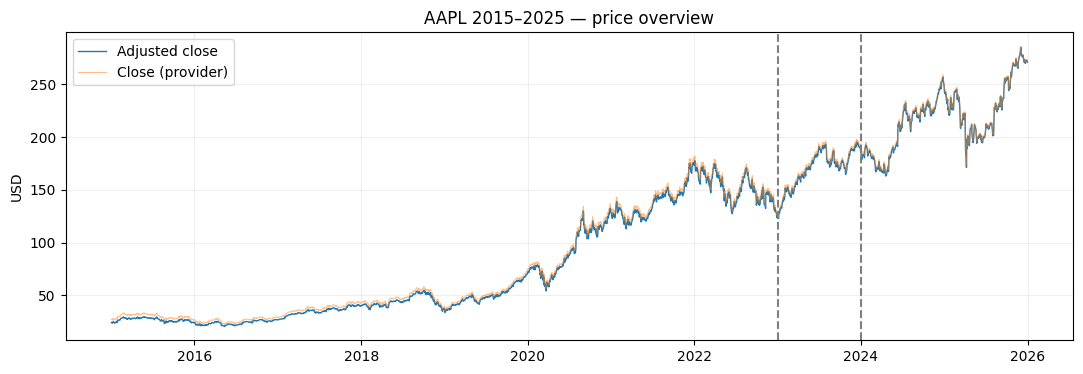

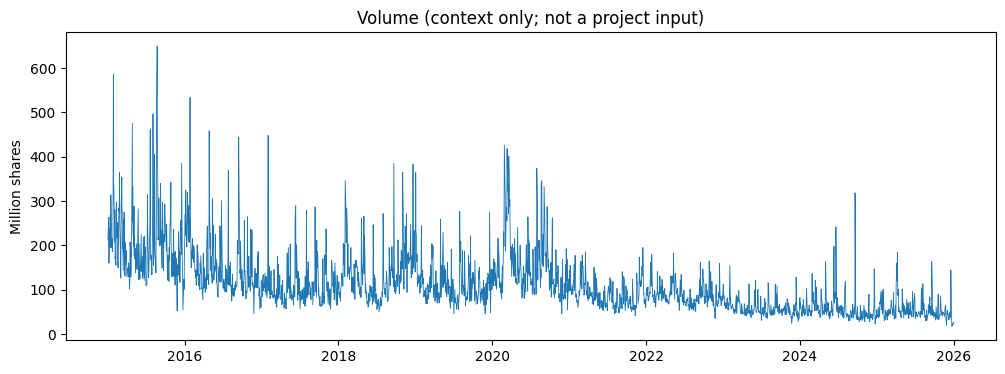

In [12]:
fig, ax = plt.subplots(figsize=(13,4))
ax.plot(eda.index, eda.adjusted_close, label='Adjusted close', linewidth=1)
if 'Close' in raw:
    ax.plot(dates, pd.to_numeric(raw.Close, errors='coerce'), label='Close (provider)', alpha=.5, linewidth=.8)
for boundary in ['2023-01-01','2024-01-01']: ax.axvline(pd.Timestamp(boundary), color='gray', linestyle='--')
ax.set(title='AAPL 2015–2025 — price overview', ylabel='USD'); ax.legend(); ax.grid(alpha=.2)
save_eda_figure(fig, 'price_overview')
plt.show()
if 'Volume' in raw:
    fig, ax = plt.subplots(); ax.plot(dates, pd.to_numeric(raw.Volume,errors='coerce')/1e6, linewidth=.6)
    ax.set(title='Volume (context only; not a project input)', ylabel='Million shares'); save_eda_figure(fig, 'volume'); plt.show()


### 7.4. Biến động theo phiên
Return = giá hôm nay / giá phiên trước − 1. Phiên đầu không có return vì thiếu phiên trước, không phải lỗi dữ liệu. Mốc |return| >10% chỉ gắn cờ, không xóa. Rolling volatility là độ lệch chuẩn mẫu (ddof=1) của 30 return gần nhất, chưa annualize; 30 phiên ở đây chỉ để minh họa, không phải kết quả tuning.

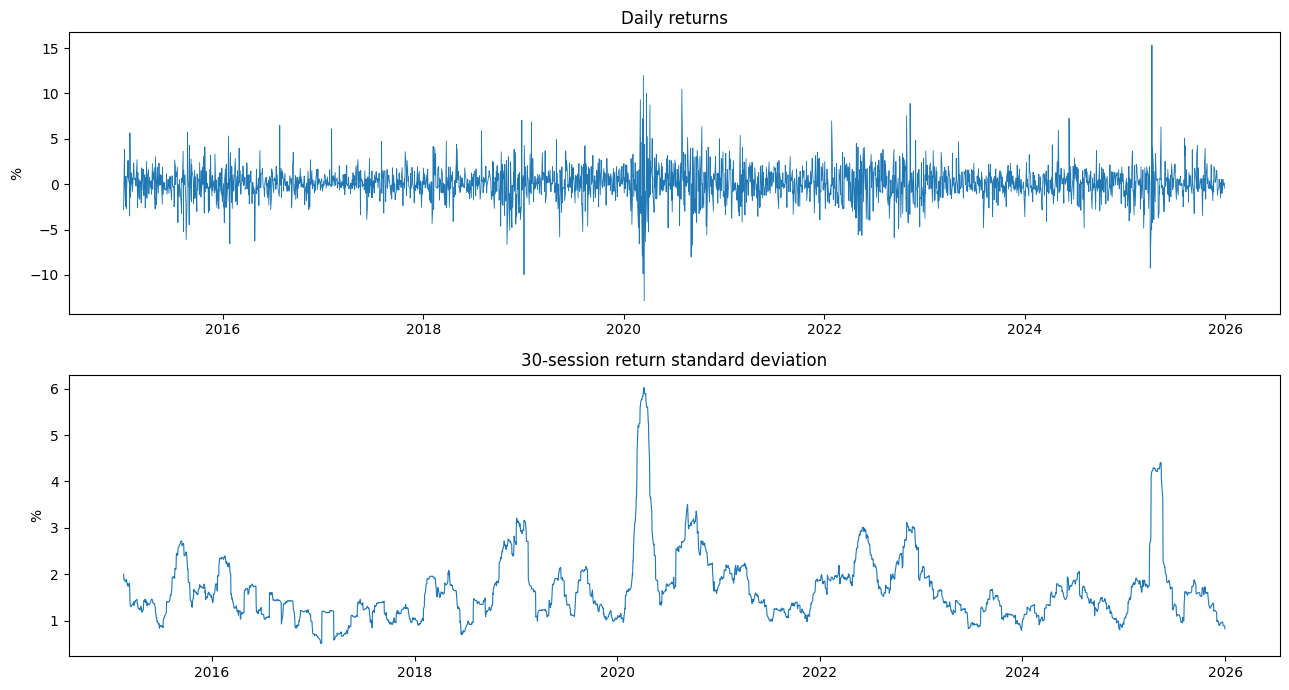

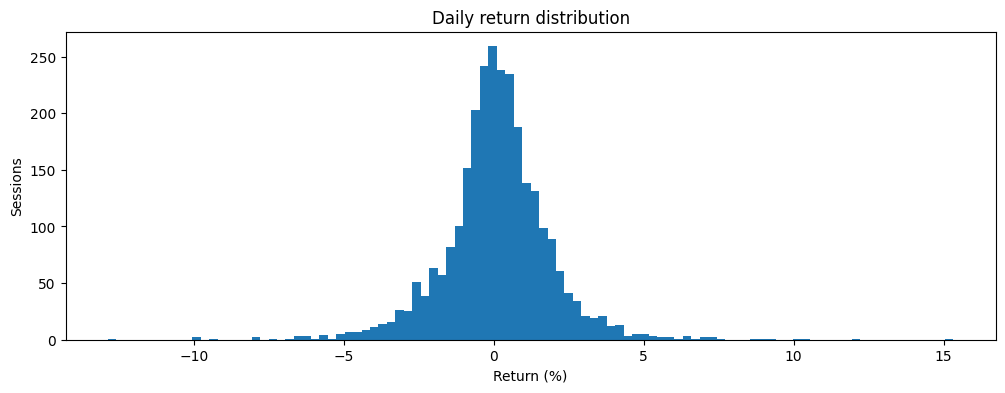

,adjusted_close,return_1d,rolling_std_30
date,,,
2020-03-16,58.375607,-0.128647,0.051271
2019-01-03,33.682331,-0.099608,0.031211
2020-03-12,59.826496,-0.098755,0.040150
2025-04-03,201.794540,-0.092456,0.023880
2020-09-03,117.060448,-0.080061,0.031055
2020-04-06,63.258507,0.087237,0.060224
2022-11-10,144.184921,0.088975,0.031193
2020-03-02,72.016891,0.093100,0.028858
2020-03-24,59.501141,0.100325,0.056223


Sessions flagged for review (absolute return >10%): 5


,adjusted_close,return_1d,rolling_std_30
date,,,
2020-03-13,66.994225,0.119809,0.046444
2020-03-16,58.375607,-0.128647,0.051271
2020-03-24,59.501141,0.100325,0.056223
2020-07-31,102.717194,0.104689,0.025395
2025-04-09,197.484360,0.153289,0.040933


In [13]:
eda['return_1d'] = eda.adjusted_close.pct_change(fill_method=None)
eda['rolling_std_30'] = eda.return_1d.rolling(30).std()
fig, axes = plt.subplots(2,1,figsize=(13,7))
axes[0].plot(eda.index, eda.return_1d*100, linewidth=.6); axes[0].set(title='Daily returns', ylabel='%')
axes[1].plot(eda.index, eda.rolling_std_30*100, linewidth=.8); axes[1].set(title='30-session return standard deviation', ylabel='%')
fig.tight_layout(); save_eda_figure(fig, 'returns_volatility'); plt.show()
fig, ax = plt.subplots(); ax.hist(eda.return_1d.dropna()*100,bins=100); ax.set(title='Daily return distribution',xlabel='Return (%)',ylabel='Sessions'); save_eda_figure(fig, 'return_histogram'); plt.show()
largest = eda.loc[eda.return_1d.abs().nlargest(12).index].sort_values('return_1d')
display(largest)
flags = eda.loc[eda.return_1d.abs()>.10]
print('Sessions flagged for review (absolute return >10%):', len(flags)); display(flags)


### 7.5. Phân bố giá và biến động theo năm

Boxplot thể hiện median và khoảng tứ phân vị; điểm ngoài whisker là quan sát xa phân bố của năm, không tự động là dữ liệu sai. Phân bố gộp cả kỳ có thể che sự thay đổi mức giá. Return loại bớt ảnh hưởng mức giá nhưng không đảm bảo ổn định phân bố. Không kết luận tính dừng hoặc khả năng dự báo chỉ bằng biểu đồ.

,sessions,min_usd,median_usd,max_usd,mean_usd,std_usd,return_count,return_std_pct
date,,,,,,,,
2015,252,23.070883,26.885528,29.519361,26.751485,1.659788,251,1.686578
2016,252,20.532551,23.933545,27.021549,23.794827,1.845094,252,1.470178
2017,251,26.648085,35.333321,41.172688,34.892570,3.541041,251,1.109055
2018,251,34.781467,43.826431,54.782188,44.483764,4.946555,251,1.810585
2019,252,33.682331,48.516144,70.605698,49.775411,8.461419,252,1.646559
2020,253,54.075951,88.577385,132.599228,92.199397,21.297153,253,2.938655
2021,252,113.046341,137.669319,176.011642,137.244984,14.485802,252,1.581273
2022,251,123.735710,150.812881,177.651413,151.559481,12.610715,251,2.248665
2023,250,122.734352,173.001915,195.575211,169.918846,17.280163,250,1.278791


,daily_return_pct
count,2765.000000
mean,0.103949
std,1.817116
min,-12.864718
1%,-4.807295
5%,-2.720134
25%,-0.728226
50%,0.095114
75%,1.001427
95%,2.837165


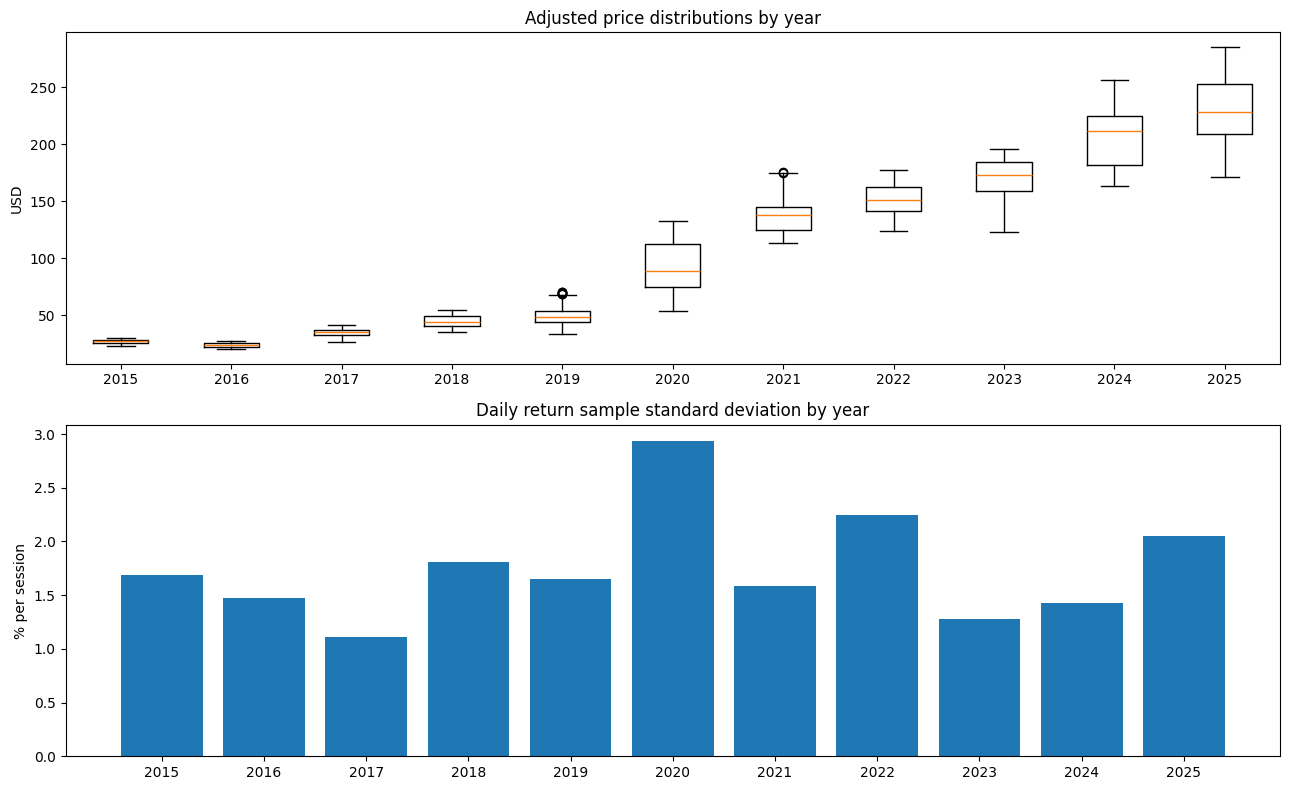

### 7.6. Nhận xét từ snapshot đang xem

- Có **2,766 phiên**, **2,765 return**; chỉ phiên đầu thiếu return do không có giá phiên trước.
- Giá điều chỉnh nằm trong **20.53–285.20 USD**, median **88.16 USD**. Đây là thống kê các quan sát theo thời gian, không phải phân bố các mẫu độc lập.
- Median giá năm 2015 là **26.89 USD**, năm 2025 là **228.86 USD**: cần chú ý mức giá thay đổi theo thời gian; không suy ra mô hình nào tốt hơn.
- Khoảng phân vị 1%–99% của return là **-4.81% đến 4.94%**; vẫn có quan sát nằm ngoài khoảng này.
- Năm **2020** có độ lệch chuẩn return lớn nhất trong bảng mô tả (**2.94%/phiên**); không quy nguyên nhân nếu chưa đối chiếu nguồn.
- **5 phiên |return| >10%** được giữ nguyên để điều tra ở mục 8; chưa có dòng nào bị xóa hoặc sửa.
- Hoàn thành EDA mục 7: bảng, hình và summary có run ID **20261119T161242679185Z**; không fit scaler/train hoặc tuning. Giá và Volume không trở thành feature mới vì có biểu đồ.


In [14]:
assert standard_output['passed'], 'Phải hoàn thành mục 6 trước khám phá'
annual = eda.groupby(eda.index.year).agg(
    sessions=('adjusted_close','size'), min_usd=('adjusted_close','min'),
    median_usd=('adjusted_close','median'), max_usd=('adjusted_close','max'),
    mean_usd=('adjusted_close','mean'), std_usd=('adjusted_close','std'),
    return_count=('return_1d','count'), return_std=('return_1d','std'))
annual['return_std_pct'] = annual.pop('return_std')*100
display(annual)
returns = eda.return_1d.dropna()
return_description = (returns*100).describe(percentiles=[.01,.05,.25,.5,.75,.95,.99])
display(return_description.to_frame('daily_return_pct'))
years = list(annual.index)
fig, axes = plt.subplots(2,1,figsize=(13,8))
axes[0].boxplot([eda.loc[eda.index.year==year,'adjusted_close'].values for year in years],tick_labels=[str(year) for year in years],showfliers=True)
axes[0].set(title='Adjusted price distributions by year',ylabel='USD')
axes[1].bar([str(year) for year in years],annual.return_std_pct)
axes[1].set(title='Daily return sample standard deviation by year',ylabel='% per session')
fig.tight_layout(); save_eda_figure(fig,'yearly_distributions'); plt.show()
price_description = eda.adjusted_close.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99])
peak_year = int(annual.return_std_pct.idxmax())
eda_result = {'dataset_version':DATASET_VERSION,'eda_run_id':EDA_RUN_ID,
    'raw_sha256':actual_hash,'validated_sha256':standard_output['hashes']['validated'],
    'rows':len(eda),'first_date':str(eda.index.min().date()),'last_date':str(eda.index.max().date()),
    'price_summary_usd':price_description.to_dict(),'return_summary_pct':return_description.to_dict(),
    'return_count':len(returns),'return_abs_gt_5pct_count':int((returns.abs()>.05).sum()),
    'return_abs_gt_10pct_count':len(flags),'highest_return_std_year':peak_year,
    'annual':annual.reset_index(names='year').to_dict(orient='records'),'figures':FIGURES,
    'limitations':['Retrospectively adjusted snapshot, not point-in-time.', 'Descriptive whole-period EDA only; no model selection on test.', 'No causal attribution or stationarity claim.']}
annual.to_csv(EDA_OUT/'annual_statistics.csv',index_label='year')
return_description.to_csv(EDA_OUT/'return_description.csv')
flags.to_csv(EDA_OUT/'flagged_moves.csv')
(EDA_OUT/'exploration_summary.json').write_text(json.dumps(eda_result,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
display(Markdown(f'''### 7.6. Nhận xét từ snapshot đang xem

- Có **{len(eda):,} phiên**, **{len(returns):,} return**; chỉ phiên đầu thiếu return do không có giá phiên trước.
- Giá điều chỉnh nằm trong **{price_description['min']:.2f}–{price_description['max']:.2f} USD**, median **{price_description['50%']:.2f} USD**. Đây là thống kê các quan sát theo thời gian, không phải phân bố các mẫu độc lập.
- Median giá năm {years[0]} là **{annual.loc[years[0],'median_usd']:.2f} USD**, năm {years[-1]} là **{annual.loc[years[-1],'median_usd']:.2f} USD**: cần chú ý mức giá thay đổi theo thời gian; không suy ra mô hình nào tốt hơn.
- Khoảng phân vị 1%–99% của return là **{return_description['1%']:.2f}% đến {return_description['99%']:.2f}%**; vẫn có quan sát nằm ngoài khoảng này.
- Năm **{peak_year}** có độ lệch chuẩn return lớn nhất trong bảng mô tả (**{annual.loc[peak_year,'return_std_pct']:.2f}%/phiên**); không quy nguyên nhân nếu chưa đối chiếu nguồn.
- **{len(flags)} phiên |return| >10%** được giữ nguyên để điều tra ở mục 8; chưa có dòng nào bị xóa hoặc sửa.
- Hoàn thành EDA mục 7: bảng, hình và summary có run ID **{EDA_RUN_ID}**; không fit scaler/train hoặc tuning. Giá và Volume không trở thành feature mới vì có biểu đồ.
'''))


### 7.7. Bằng chứng và công việc còn lại
Notebook chỉ mô tả, không tự sửa giá hay loại phiên. Kết quả không thay thế xác nhận người nhận độc lập hoặc điều tra nguyên nhân biến động ở mục 8.

In [15]:
summary = {'origin':origin, 'raw_file':raw_path.relative_to(ROOT).as_posix() if raw_path.is_relative_to(ROOT) else str(raw_path), 'actual_sha256':actual_hash, 'checks':checks.to_dict(), 'calendar_reference':'XNYS / exchange_calendars '+importlib.metadata.version('exchange_calendars'), 'missing_sessions':missing_sessions.strftime('%Y-%m-%d').tolist(), 'unexpected_sessions':unexpected_sessions.strftime('%Y-%m-%d').tolist(), 'flagged_returns_gt_10pct':len(flags)}
(OUT/'eda_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
coverage.to_csv(OUT/'session_coverage.csv')
largest.to_csv(OUT/'largest_daily_moves.csv')
display(Markdown(f'''**Kết quả snapshot đang xem:** {len(eda):,} dòng, từ {eda.index.min().date()} đến {eda.index.max().date()}; thiếu {len(missing_sessions)} phiên và thừa {len(unexpected_sessions)} phiên so với lịch tham chiếu. Có {len(flags)} biến động >10% cần xem xét, không tự loại.

**TV1 cần hoàn thiện:**
1. Bàn giao snapshot gốc/validated/metadata/report đúng hash cùng nơi tải cụ thể; đối chiếu lại notebook trên bộ đó.
2. Đã tích hợp audit lịch phiên/độ phủ vào validator (hạng mục 5); lịch NASDAQ của thư viện là alias XNYS, cần ghi giới hạn khi báo cáo.
3. Đã bổ sung kiểm tra metadata (hạng mục 3) và chặn ghi đè snapshot (hạng mục 4); tiếp tục kiểm thử trong pipeline tích hợp.
4. Bổ sung đồ thị, bảng biến động lớn và giải thích có nguồn cho từng điểm cần điều tra; không tự suy đoán nguyên nhân.
5. Thêm tests ngày sai, NaN/Inf, rỗng, thiếu cột/phiên, metadata/hash sai; lưu kết quả chạy sạch.
6. Bổ sung dependencies và hướng dẫn nhận artifacts/chạy từ môi trường sạch.

**Ngoài trách nhiệm TV1:** fit scaler, chia target theo thời gian và windowing thuộc TV2. Chưa train model trong notebook này.'''))


**Kết quả snapshot đang xem:** 2,766 dòng, từ 2015-01-02 đến 2025-12-31; thiếu 0 phiên và thừa 0 phiên so với lịch tham chiếu. Có 5 biến động >10% cần xem xét, không tự loại.

**TV1 cần hoàn thiện:**
1. Bàn giao snapshot gốc/validated/metadata/report đúng hash cùng nơi tải cụ thể; đối chiếu lại notebook trên bộ đó.
2. Đã tích hợp audit lịch phiên/độ phủ vào validator (hạng mục 5); lịch NASDAQ của thư viện là alias XNYS, cần ghi giới hạn khi báo cáo.
3. Đã bổ sung kiểm tra metadata (hạng mục 3) và chặn ghi đè snapshot (hạng mục 4); tiếp tục kiểm thử trong pipeline tích hợp.
4. Bổ sung đồ thị, bảng biến động lớn và giải thích có nguồn cho từng điểm cần điều tra; không tự suy đoán nguyên nhân.
5. Thêm tests ngày sai, NaN/Inf, rỗng, thiếu cột/phiên, metadata/hash sai; lưu kết quả chạy sạch.
6. Bổ sung dependencies và hướng dẫn nhận artifacts/chạy từ môi trường sạch.

**Ngoài trách nhiệm TV1:** fit scaler, chia target theo thời gian và windowing thuộc TV2. Chưa train model trong notebook này.

<a id="tv1-hang-muc-8"></a>

## Hạng mục 8 — Điều tra quan sát bất thường (TV1)

### 8.1. Quy tắc và giới hạn

Tiếp nối mục 7: xem **tất cả phiên có |return Adj Close| >10%**, không chọn riêng ví dụ thuận lợi. Đây không phải toàn bộ lỗi có thể xảy ra. So sánh return Close và Adj Close, hệ số Adj Close/Close, OHLC/Volume và hai phiên trước/sau. Dữ liệu tương lai và tin tức chỉ phục vụ audit hồi cứu, tuyệt đối không chuyển thành input model.

Nếu return tương tự ở cả Close và Adj Close, chưa thấy biến động chỉ do hệ số điều chỉnh; điều đó **không xác thực độc lập giá Yahoo**. Tin tức cùng thời điểm chỉ là bối cảnh, không chứng minh nguyên nhân duy nhất. Không xóa, nội suy, winsorize hoặc điều chỉnh chia tách thêm nếu chưa có bằng chứng lỗi.

Nguồn và ngày công bố được ghi ở `reports/audits/TV1_Anomaly_Sources.json`. Notebook đọc ledger cục bộ, không tải mạng khi Run All. Tin trong phiên không được dùng làm return đóng cửa.

In [16]:
ledger_path = ROOT / 'reports/audits/TV1_Anomaly_Sources.json'
ledger = json.loads(ledger_path.read_text(encoding='utf-8'))
event_notes = {event['date']:event for event in ledger['events']}
work = raw.copy().reset_index(drop=True)
work['adj_return_pct'] = work['Adj Close'].pct_change(fill_method=None)*100
work['close_return_pct'] = work['Close'].pct_change(fill_method=None)*100
work['adjustment_factor'] = work['Adj Close']/work['Close']
work['factor_change_pct'] = work.adjustment_factor.pct_change(fill_method=None)*100
event_indices = work.index[work.adj_return_pct.abs()>10].tolist()
observed_event_dates = work.loc[event_indices,'date'].tolist()
assert set(observed_event_dates) == set(event_notes), 'Ledger chưa bao phủ đúng các phiên được gắn cờ; cần điều tra bổ sung'
event_rows, windows = [], []
for i in event_indices:
    row = work.loc[i]; note = event_notes[row['date']]
    event_rows.append({'date':row['date'],'previous_session':work.loc[i-1,'date'],
        'previous_adjusted_close':float(work.loc[i-1,'Adj Close']), 'adjusted_close':float(row['Adj Close']),
        'adjusted_return_pct':float(row.adj_return_pct),'close_return_pct':float(row.close_return_pct),
        'return_gap_percentage_points':float(row.adj_return_pct-row.close_return_pct),
        'adjustment_factor_change_pct':float(row.factor_change_pct), 'volume':int(row.Volume),
        'close_return_also_exceeds_10pct':bool(abs(row.close_return_pct)>10),
        'decision':note['decision'],'evidence_level':note['evidence_level']})
    window = work.iloc[max(0,i-2):min(len(work),i+3)].copy()
    window.insert(0,'event_date',row['date'])
    windows.append(window)
event_table = pd.DataFrame(event_rows)
window_table = pd.concat(windows,ignore_index=True)
display(event_table)
display(window_table[['event_date','date','Adj Close','Close','Open','High','Low','Volume','adj_return_pct','adjustment_factor']])
assert event_table.close_return_also_exceeds_10pct.all()
assert (event_table.return_gap_percentage_points.abs()<.01).all(), 'Cần điều tra thêm chênh lệch return Close/Adj Close'
display(Markdown('**Quan sát kỹ thuật:** cả 5 phiên biến động >10% ở cả hai chuỗi; chênh lệch return dưới 0,01 điểm phần trăm. Chưa thấy bằng chứng đây là cú nhảy chỉ do hệ số điều chỉnh. Mốc 0,01 chỉ phục vụ đối chiếu trong audit, không là ngưỡng sửa dữ liệu.'))


,date,previous_session,previous_adjusted_close,adjusted_close,adjusted_return_pct,close_return_pct,return_gap_percentage_points,adjustment_factor_change_pct,volume,close_return_also_exceeds_10pct,decision,evidence_level
0,2020-03-13,2020-03-12,59.826496,66.994225,11.980859,11.980827,0.000033,0.000029,370732000,True,retain_no_correction_evidence,market_context_supported; stock-specific causa...
1,2020-03-16,2020-03-13,66.994225,58.375607,-12.864718,-12.864696,-0.000022,-0.000026,322423600,True,retain_no_correction_evidence,market_context_supported; stock-specific causa...
2,2020-03-24,2020-03-23,54.075951,59.501141,10.032537,10.032540,-0.000003,-0.000002,287531200,True,retain_no_correction_evidence,market_context_supported; stock-specific causa...
3,2020-07-31,2020-07-30,92.982933,102.717194,10.468868,10.468863,0.000005,0.000004,374336800,True,retain_no_correction_evidence,issuer_event_confirmed; contemporary AAPL rall...
4,2025-04-09,2025-04-08,171.235840,197.484360,15.328870,15.328853,0.000017,0.000015,184395900,True,retain_no_correction_evidence,market_and_AAPL_intraday_context_supported; cl...


,event_date,date,Adj Close,Close,Open,High,Low,Volume,adj_return_pct,adjustment_factor
0,2020-03-13,2020-03-11,66.382034,68.857498,69.347504,70.305000,67.964996,255598800,-3.473043,0.964049
1,2020-03-13,2020-03-12,59.826496,62.057499,63.985001,67.500000,62.000000,418474000,-9.875470,0.964049
2,2020-03-13,2020-03-13,66.994225,69.492500,66.222504,69.980003,63.237499,370732000,11.980859,0.964050
3,2020-03-13,2020-03-16,58.375607,60.552502,60.487499,64.769997,60.000000,322423600,-12.864718,0.964049
4,2020-03-13,2020-03-17,60.942375,63.215000,61.877499,64.402496,59.599998,324056000,4.396988,0.964049
5,2020-03-16,2020-03-12,59.826496,62.057499,63.985001,67.500000,62.000000,418474000,-9.875470,0.964049
6,2020-03-16,2020-03-13,66.994225,69.492500,66.222504,69.980003,63.237499,370732000,11.980859,0.964050
7,2020-03-16,2020-03-16,58.375607,60.552502,60.487499,64.769997,60.000000,322423600,-12.864718,0.964049
8,2020-03-16,2020-03-17,60.942375,63.215000,61.877499,64.402496,59.599998,324056000,4.396988,0.964049
9,2020-03-16,2020-03-18,59.450523,61.667500,59.942501,62.500000,59.279999,300233600,-2.447971,0.964050


**Quan sát kỹ thuật:** cả 5 phiên biến động >10% ở cả hai chuỗi; chênh lệch return dưới 0,01 điểm phần trăm. Chưa thấy bằng chứng đây là cú nhảy chỉ do hệ số điều chỉnh. Mốc 0,01 chỉ phục vụ đối chiếu trong audit, không là ngưỡng sửa dữ liệu.

### 8.2. Bối cảnh có nguồn và quyết định

Các nguồn bên dưới xác nhận sự kiện/bối cảnh; số return trong bảng được tính từ snapshot, không chép từ tin tức. Phân biệt ngày xuất bản với ngày phiên giao dịch, và thông báo chia tách với ngày thực hiện.

In [17]:
for event in ledger['events']:
    sources = ' · '.join(f"[{s['publisher']} ({s['published_date']})]({s['url']})" for s in event['sources'])
    display(Markdown(f"**{event['date']}** — {event['context']}\n\nNguồn: {sources}\n\nMức bằng chứng: `{event['evidence_level']}`. Quyết định: **giữ nguyên**, chưa có bằng chứng sửa giá."))
display(Markdown('**Phân biệt quan trọng:** Apple công bố kết quả và thông báo split ngày 30/07/2020; giao dịch theo split bắt đầu 31/08/2020. Mức tăng ngày 31/07 không phải mức tăng cơ học vì hôm đó thực hiện split. Không chia giá trong CSV thêm 4 lần. [Apple xác nhận lịch](https://www.apple.com/newsroom/2020/07/apple-reports-third-quarter-results/).'))


**2020-03-13** — Thị trường phục hồi cùng thông báo tình trạng khẩn cấp COVID-19. Đây là bối cảnh thị trường, chưa chứng minh nguyên nhân riêng của AAPL.

Nguồn: [Reuters / Investing.com (2020-03-13)](https://ng.investing.com/news/stock-market-news/global-marketslate-wall-street-rally-leads-global-stocks-higher-oil-also-jumps-153143)

Mức bằng chứng: `market_context_supported; stock-specific causality not established`. Quyết định: **giữ nguyên**, chưa có bằng chứng sửa giá.

**2020-03-16** — Thị trường bán tháo trong lo ngại tác động COVID-19, dù Fed vừa hạ lãi suất. Bối cảnh phù hợp với chiều giảm trong snapshot; chưa xác định quan hệ nhân quả.

Nguồn: [Reuters / Investing.com (2020-03-16)](https://ng.investing.com/news/stock-market-news/us-stockswall-st-sinks-as-virus-spread-escalates-worries-154288?ampMode=1)

Mức bằng chứng: `market_context_supported; stock-specific causality not established`. Quyết định: **giữ nguyên**, chưa có bằng chứng sửa giá.

**2020-03-24** — Thị trường tăng trong kỳ vọng gói hỗ trợ tài khóa Mỹ. Nguồn ngày 25/03 mô tả phiên 24/03; phân biệt ngày báo cáo và ngày giao dịch.

Nguồn: [Standard Chartered (2020-03-25)](https://www.sc.com/en/uploads/sites/66/content/docs/pvb-market-watch-us-close-to-sealing-usd2tn-stimulus-25-march-2020.pdf)

Mức bằng chứng: `market_context_supported; stock-specific causality not established`. Quyết định: **giữ nguyên**, chưa có bằng chứng sửa giá.

**2020-07-31** — Phiên sau công bố kết quả kinh doanh và thông báo chia tách của Apple ngày 30/07. Giao dịch theo split bắt đầu 31/08/2020; không phải 31/07. Không chia giá thêm lần nữa.

Nguồn: [Apple Newsroom (2020-07-30)](https://www.apple.com/newsroom/2020/07/apple-reports-third-quarter-results/) · [The Motley Fool (2020-07-31)](https://www.fool.com/investing/2020/07/31/why-apple-stock-soared-to-a-new-all-time-high-toda.aspx)

Mức bằng chứng: `issuer_event_confirmed; contemporary AAPL rally reported; causality not isolated`. Quyết định: **giữ nguyên**, chưa có bằng chứng sửa giá.

**2025-04-09** — Thị trường phục hồi sau thông báo tạm hoãn nhiều thuế quan trong 90 ngày, ngoại trừ Trung Quốc. MacRumors là tin trong phiên; không dùng mức tăng trong bài làm return đóng cửa.

Nguồn: [Reuters / Kitco (2025-04-09)](https://www.kitco.com/news/off-the-wire/2025-04-09/stocks-spring-higher-dollar-gains-trump-announces-tariff-pause) · [MacRumors (2025-04-09)](https://www.macrumors.com/2025/04/09/apple-stock-up-tariff-pause/)

Mức bằng chứng: `market_and_AAPL_intraday_context_supported; closing return from local snapshot`. Quyết định: **giữ nguyên**, chưa có bằng chứng sửa giá.

**Phân biệt quan trọng:** Apple công bố kết quả và thông báo split ngày 30/07/2020; giao dịch theo split bắt đầu 31/08/2020. Mức tăng ngày 31/07 không phải mức tăng cơ học vì hôm đó thực hiện split. Không chia giá trong CSV thêm 4 lần. [Apple xác nhận lịch](https://www.apple.com/newsroom/2020/07/apple-reports-third-quarter-results/).

### 8.3. Hình đối chiếu, kết luận và bằng chứng

Mỗi panel dùng hai phiên trước/sau, quy giá phiên đầu cửa sổ về 100 để so hình dạng Close/Adj Close. Hai đường gần trùng nhau là kết quả đối chiếu nội bộ cùng nguồn, không phải hai nhà cung cấp độc lập. Các phiên sau sự kiện chỉ để điều tra hồi cứu.

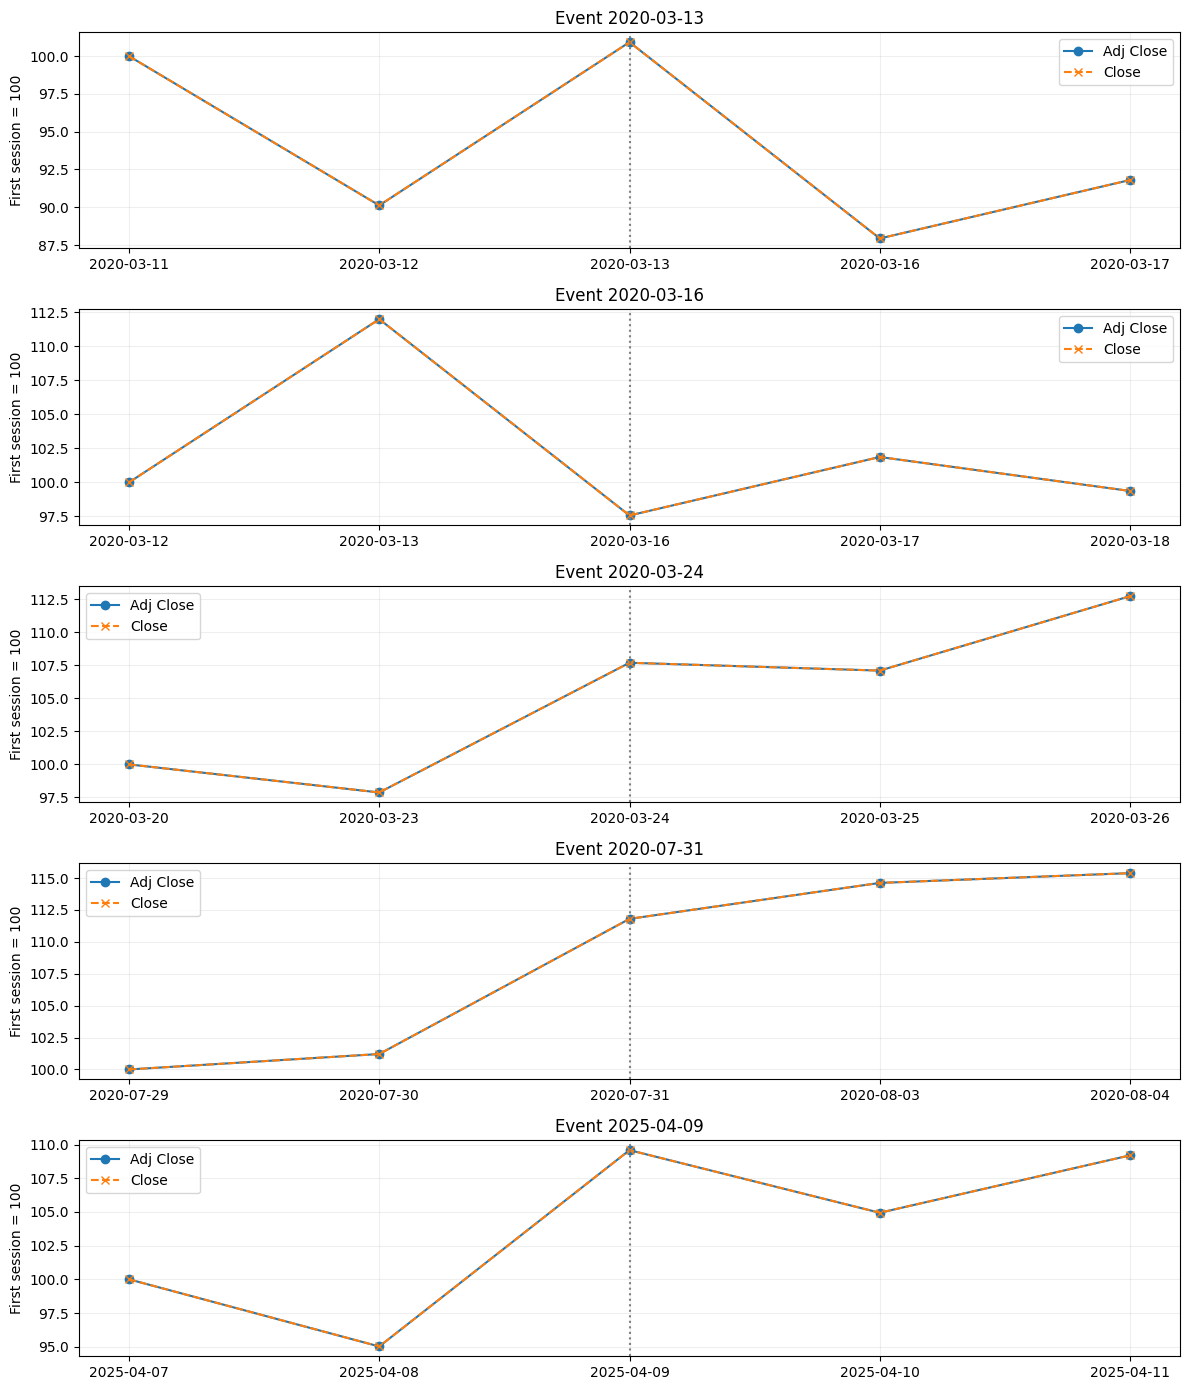

**Hoàn thành hạng mục 8 ở phạm vi đã chọn:** đã đối chiếu 5/5 phiên gắn cờ, ghi nguồn và mức bằng chứng, giữ cả 5 phiên. Không sửa/xóa dòng, raw và validated giữ nguyên hash. Báo cáo và CSV tại `data\metadata\eda\aapl_2015_2025_acq_20261119T141302002415Z\20261119T161242679185Z\anomaly_review`. Bước tiếp theo là hạng mục 9: kiểm thử và tổng hợp bằng chứng.

In [18]:
fig, axes = plt.subplots(len(event_indices),1,figsize=(12,14),squeeze=False)
for ax, i in zip(axes.ravel(),event_indices):
    window = work.iloc[max(0,i-2):min(len(work),i+3)]
    x = np.arange(len(window))
    ax.plot(x,window['Adj Close']/window['Adj Close'].iloc[0]*100,'o-',label='Adj Close')
    ax.plot(x,window['Close']/window['Close'].iloc[0]*100,'x--',label='Close')
    ax.axvline(i-window.index[0],color='gray',linestyle=':')
    ax.set_xticks(x,window.date.tolist()); ax.set(title=f"Event {work.loc[i,'date']}",ylabel='First session = 100')
    ax.grid(alpha=.2); ax.legend(loc='best')
fig.tight_layout(); save_eda_figure(fig,'anomaly_event_windows'); plt.show()
anomaly_dir = OUT / EDA_RUN_ID / 'anomaly_review'
anomaly_dir.mkdir(parents=True,exist_ok=True)
event_table.to_csv(anomaly_dir/'event_review.csv',index=False)
window_table.to_csv(anomaly_dir/'event_windows.csv',index=False)
review = {'dataset_version':DATASET_VERSION,'review_run_id':EDA_RUN_ID,'raw_sha256':actual_hash,
    'validated_sha256':standard_output['hashes']['validated'],'sources_sha256':hashlib.sha256(ledger_path.read_bytes()).hexdigest(),
    'event_count':len(event_table),'rows_removed':0,'values_changed':0,'decision':'retain_all_flagged_rows',
    'events':event_rows,'sources':ledger,'figure':FIGURES[-1],
    'limitations':['Contextual evidence is not causal identification.', 'No independent exchange-level validation of every price.', 'Other anomalies below threshold are not ruled out.', 'No news/future-window features for forecasting.']}
assert hashlib.sha256(raw_path.read_bytes()).hexdigest()==actual_hash
assert hashlib.sha256(validated_path.read_bytes()).hexdigest()==standard_output['hashes']['validated']
(anomaly_dir/'anomaly_review.json').write_text(json.dumps(review,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
display(Markdown(f"**Hoàn thành hạng mục 8 ở phạm vi đã chọn:** đã đối chiếu 5/5 phiên gắn cờ, ghi nguồn và mức bằng chứng, giữ cả 5 phiên. Không sửa/xóa dòng, raw và validated giữ nguyên hash. Báo cáo và CSV tại `{anomaly_dir.relative_to(ROOT)}`. Bước tiếp theo là hạng mục 9: kiểm thử và tổng hợp bằng chứng."))


<a id="tv1-hang-muc-9"></a>

## Hạng mục 9 — Tổng hợp kiểm thử TV1

### 9.1. Phạm vi và lệnh chạy

Kiểm thử dữ liệu trước preprocessing, đúng flow 1–8 → 9. Bao gồm schema/ngày/giá/lịch phiên/OHLCV, provenance, chặn ghi đè, bảng chuẩn, pipeline offline và gói ZIP bàn giao. Không kiểm thử scaler/windowing/training của TV2–TV5 ở đây.

```powershell
.venv/eda/Scripts/python.exe scripts/run_tv1_checks.py --dataset-version aapl_2015_2025_acq_20261119T141302002415Z
```

Runner tạo `logs/audit/tv1_tests_<run_id>/summary.json` và `unittest.log`; lỗi, skip hoặc artifacts thay đổi sẽ trả exit code khác 0. Tests pipeline dùng dữ liệu tổng hợp được gắn nhãn và mock download; tests artifacts dùng bộ snapshot/ZIP thật tại máy, không gọi Yahoo/Drive. Không sửa source dataset hoặc giả xác nhận người nhận ở máy khác.

Cell dưới **đọc kết quả đã chạy**, không tự chạy lại tests khi Run All; chọn lần chạy mới nhất của đúng dataset version, không bỏ qua một lần fail mới hơn để lấy lần pass cũ.

In [19]:
candidate_reports = []
for path in sorted((ROOT/'logs/audit').glob('tv1_tests_*/summary.json')):
    item = json.loads(path.read_text(encoding='utf-8'))
    if item.get('dataset_version') == DATASET_VERSION:
        candidate_reports.append((path,item))
assert candidate_reports, 'Chạy scripts/run_tv1_checks.py trước'
tests_path, tests_result = candidate_reports[-1]
display(pd.Series({key:tests_result[key] for key in ['run_id','dataset_version','passed','tests_run','failures','errors','skipped','artifacts_unchanged','recipient_verified']},name='TV1 tests').to_frame())
test_records = pd.DataFrame(tests_result['records'])
test_records['module'] = test_records.test.str.split('.').str[0]
display(test_records.groupby(['module','status']).size().unstack(fill_value=0))
display(test_records[['test','status']])
log_path = ROOT/tests_result['log_file']
assert hashlib.sha256(log_path.read_bytes()).hexdigest()==tests_result['unittest_log_sha256'], 'Log bị thay đổi'
for name, expected_hash in tests_result['artifact_hashes'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==expected_hash, f'Artifact đã thay đổi: {name}'
for name, expected_hash in tests_result['source_hashes'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==expected_hash, f'Source đã đổi, cần chạy lại tests: {name}'
assert tests_result['passed'] and tests_result['skipped']==0, 'Bộ kiểm thử chưa đạt đầy đủ'
display(Markdown(f"**Hoàn thành hạng mục 9 trên máy hiện tại:** {tests_result['tests_run']}/{tests_result['tests_run']} test đạt, không skip; hash artifacts và source khớp bằng chứng. [Log đầy đủ](../{tests_result['log_file']}) · [Summary JSON](../{tests_path.relative_to(ROOT).as_posix()}). Chưa thay thế kiểm tra trên máy thành viên khác."))
print(log_path.read_text(encoding='utf-8'))


,TV1 tests
run_id,20261119T160931135922Z
dataset_version,aapl_2015_2025_acq_20261119T141302002415Z
passed,True
tests_run,34
failures,0
errors,0
skipped,0
artifacts_unchanged,True
recipient_verified,False


status,passed
module,
test_data_pipeline,4
test_data_quality,7
test_handoff_integrity,6
test_pipeline_integration,4
test_provenance,4
test_snapshot_versioning,5
test_standard_output,4


,test,status
0,test_data_pipeline.TestDataValidationPipeline....,passed
1,test_data_pipeline.TestDataValidationPipeline....,passed
2,test_data_pipeline.TestDataValidationPipeline....,passed
3,test_data_pipeline.TestDataValidationPipeline....,passed
4,test_data_quality.TestDataQuality.test_auxilia...,passed
5,test_data_quality.TestDataQuality.test_bad_dat...,passed
6,test_data_quality.TestDataQuality.test_complet...,passed
7,test_data_quality.TestDataQuality.test_empty_a...,passed
8,test_data_quality.TestDataQuality.test_large_m...,passed
9,test_data_quality.TestDataQuality.test_missing...,passed


**Hoàn thành hạng mục 9 trên máy hiện tại:** 34/34 test đạt, không skip; hash artifacts và source khớp bằng chứng. [Log đầy đủ](../logs/audit/tv1_tests_20261119T160931135922Z/unittest.log) · [Summary JSON](../logs/audit/tv1_tests_20261119T160931135922Z/summary.json). Chưa thay thế kiểm tra trên máy thành viên khác.

test_duplicate_dates_rejected (test_data_pipeline.TestDataValidationPipeline.test_duplicate_dates_rejected) ... ok
test_generated_aapl_artifacts_integrity (test_data_pipeline.TestDataValidationPipeline.test_generated_aapl_artifacts_integrity)
Kiểm tra bộ dữ liệu AAPL thật đã tạo trong thư mục data/. ... ok
test_missing_or_non_positive_price_rejected (test_data_pipeline.TestDataValidationPipeline.test_missing_or_non_positive_price_rejected) ... ok
test_valid_dataframe_passes (test_data_pipeline.TestDataValidationPipeline.test_valid_dataframe_passes) ... ok
test_auxiliary_ohlc_and_volume_checked (test_data_quality.TestDataQuality.test_auxiliary_ohlc_and_volume_checked) ... ok
test_bad_dates_prices_duplicates_and_order_rejected (test_data_quality.TestDataQuality.test_bad_dates_prices_duplicates_and_order_rejected) ... ok
test_complete_sessions_pass (test_data_quality.TestDataQuality.test_complete_sessions_pass) ... ok
test_empty_and_missing_columns_rejected (test_data_quality.TestDataQual

<a id="tv1-hang-muc-10"></a>

## Hạng mục 10 — Tài liệu và tái lập TV1

### 10.1. Hướng dẫn chính

[Mở hướng dẫn cài đặt và tái lập](../docs/TV1_Setup_and_Reproduce.md): nhận source hiện tại (chưa mặc định đã merge GitHub), tải ZIP/checksum đúng version từ Drive, dựng Python 3.13 venv sạch với dependencies ghim, verify ZIP, chạy tests rồi notebook. Có hướng dẫn kernel VS Code, lỗi thường gặp và thông tin người nhận cần phản hồi.

```powershell
python -m venv .venv/eda
.venv/eda/Scripts/python.exe -m pip install -r notebooks/requirements-eda.txt
.venv/eda/Scripts/python.exe scripts/run_tv1_checks.py --dataset-version aapl_2015_2025_acq_20261119T141302002415Z
python scripts/execute_data_exploration.py
```

Tạo venv ở đường dẫn mới, không kế thừa system/user packages. Nhận đủ artifacts và receipt trước khi chạy. Không cần download lại Yahoo, fit scaler hoặc train để xem dữ liệu.

### 10.2. Kiểm chứng tái lập cục bộ

`scripts/check_tv1_reproducibility.py` dựng bản source riêng, nhận data từ ZIP đã xác minh và chạy bằng Python sạch được chỉ định. Kiểm tra pip check, lưu freeze, chạy tests và toàn bộ notebook. Kết quả này chỉ chứng minh tái lập trên **cùng máy**, chưa phải nghiệm thu máy thành viên khác. Notebook đọc bằng chứng đã tạo; không tự cài dependencies hoặc chạy quy trình lồng nhau khi Run All.

In [20]:
reproduction_path = ROOT/'data/metadata/tv1_reproducibility_latest.json'
if reproduction_path.is_file():
    reproduction = json.loads(reproduction_path.read_text(encoding='utf-8'))
    assert reproduction['dataset_version']==DATASET_VERSION
    display(pd.Series({key:reproduction[key] for key in ['run_id','passed','tests_run','notebook_code_cells','notebook_passed','same_machine_only','independent_recipient_verified','evidence_folder','requirements_freeze']},name='Reproduction').to_frame())
    assert reproduction['passed'], 'Tái lập cục bộ chưa đạt; xem log'
    display(Markdown(f"**Đã kiểm chứng trong venv sạch và workspace riêng trên cùng máy.** [Hồ sơ tái lập](../{reproduction['evidence_folder']}/summary.json) · [Dependencies freeze](../{reproduction['requirements_freeze']}). **Chờ xác nhận máy thành viên khác**, không đánh dấu đạt thay người nhận."))
else:
    display(Markdown('**Chưa có bằng chứng tái lập trong workspace này.** Làm theo docs/TV1_Setup_and_Reproduce.md; không tự ghi đạt. Trường hợp đang chạy bản sao kiểm chứng lần đầu, summary chỉ được tạo sau khi notebook hoàn tất.'))


,Reproduction
run_id,20261119T160957436492Z
passed,True
tests_run,34
notebook_code_cells,20
notebook_passed,True
same_machine_only,True
independent_recipient_verified,False
evidence_folder,logs/audit/tv1_repro_20261119T160957436492Z
requirements_freeze,logs/audit/tv1_repro_20261119T160957436492Z/re...


**Đã kiểm chứng trong venv sạch và workspace riêng trên cùng máy.** [Hồ sơ tái lập](../logs/audit/tv1_repro_20261119T160957436492Z/summary.json) · [Dependencies freeze](../logs/audit/tv1_repro_20261119T160957436492Z/requirements-freeze.txt). **Chờ xác nhận máy thành viên khác**, không đánh dấu đạt thay người nhận.

### 10.3. Checklist người nhận

- Có đúng source mới nhất, snapshot version và ZIP checksum đã chỉ định.
- Verify ZIP đạt, raw/validated 2.766 dòng, schema bốn cột; không tự tải bộ thay thế.
- Tests không fail/error/skip, notebook chạy đủ cell, hash dataset không đổi.
- Gửi OS/Python, version/hash ZIP, log/summary và ngày thực hiện để xác nhận độc lập.

**Giới hạn còn mở:** chưa có phản hồi chạy trên máy khác; lịch tham chiếu NASDAQ alias XNYS; metadata/hashes không xác thực độc lập nhà cung cấp; bối cảnh sự kiện không chứng minh nguyên nhân duy nhất. Phần TV2 preprocessing/model/train/API/web chưa được nghiệm thu trong TV1.